# First model: article topic from text

Predict one of eight topic labels from an article's title and body.

The training file is `data/clean/articles_single.csv`. It keeps articles with at least 100 words and exactly one label from the grouping in `topic_grouping.md`. The original export and the file that still contains multi-label articles are left unchanged.

This notebook fits one baseline: TF–IDF features and logistic regression. Run it from the project directory.

## Load the single-label articles

Each row is one article. `label` is the class to predict. `topics` still holds the original fine-grained tags, joined with `|`, so the mapping can be checked later.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

DATA_PATH = Path("data/clean/articles_single.csv")
RANDOM_STATE = 42

articles = pd.read_csv(DATA_PATH)
articles["body_words"] = articles["body"].fillna("").str.split().str.len()

print(f"Rows: {len(articles):,}")
print(f"Columns: {list(articles.columns)}")
print(f"Shortest body: {articles['body_words'].min()} words")
print(f"Labels with more than one class: {(articles['label'].str.contains('|', regex=False)).sum()}")

Rows: 13,584
Columns: ['uuid', 'title', 'published_at', 'publisher', 'original_url', 'topics', 'label', 'body', 'body_words']
Shortest body: 100 words
Labels with more than one class: 0


## Class sizes

Sports is about a third of the set, and politics is the smallest class. Accuracy alone would reward predicting the large classes, so the model is judged with macro-F1 as well as accuracy.

In [2]:
class_counts = articles["label"].value_counts()
class_share = (class_counts / len(articles) * 100).round(1)
pd.DataFrame({"articles": class_counts, "percent": class_share})

,articles,percent
label,,
sports,4334,31.9
science_nature,1731,12.7
technology,1674,12.3
entertainment_culture,1525,11.2
lifestyle,1492,11.0
health,1062,7.8
business_finance,1058,7.8
politics_society,708,5.2


## Text given to the model

The classifier reads the title and the body as one string. The title is short, but it usually names the subject of the article.

Emojis, URLs, and HTML entities are left in the text. The TF–IDF tokenizer below keeps word tokens, so those symbols do not become features.

In [3]:
articles["text"] = (
    articles["title"].fillna("").str.strip()
    + "\n"
    + articles["body"].fillna("").str.strip()
)

print(articles.loc[0, "label"])
print(articles.loc[0, "text"][:400])

sports
WATCH | Bafana receive hearty welcome at OR Tambo International Airport
Bafana Bafana have received a warm welcome from cheering fans and dignitaries at OR Tambo International Airport. Supporters are happy with the team for making history at the FIFA World Cup by reaching the round of 32 stage. Bafana Bafana return to the country after losing to Canada at the tournament. Hundreds of fans braved th


## Train, validation, and test split

The split is 70% train, 15% validation, and 15% test. It is stratified on `label`, so each class keeps the same share in every part. `random_state=42` makes the split repeatable.

The vectorizer and the classifier are fit on the training part only. Validation is for checking this first model. The test part is scored once, after that.

In [4]:
train_df, held_out_df = train_test_split(
    articles,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=articles["label"],
)
val_df, test_df = train_test_split(
    held_out_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=held_out_df["label"],
)

split_sizes = pd.Series(
    {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
)
split_sizes

train         9508
validation    2038
test          2038
dtype: int64

## TF–IDF features and logistic regression

Each article becomes a TF–IDF vector of word and word-pair counts. English stop words are removed. A term must appear in at least two training articles, and only the 50,000 most frequent terms are kept. `sublinear_tf` dampens raw counts, so a word repeated many times in one long article does not dominate that article.

Logistic regression then predicts one of the eight labels. `class_weight="balanced"` gives the smaller classes more influence during training, because sports would otherwise dominate the loss.

In [5]:
model = Pipeline(
    [
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_features=50_000,
                sublinear_tf=True,
            ),
        ),
        (
            "clf",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

model.fit(train_df["text"], train_df["label"])
print(f"Vocabulary size: {len(model.named_steps['tfidf'].vocabulary_):,}")

Vocabulary size: 50,000


## Validation score

Accuracy is the share of articles with the correct label. Macro-F1 is the unweighted mean of the per-class F1 scores, so a small class counts as much as sports.

In [6]:
def score_split(name, frame):
    predicted = model.predict(frame["text"])
    accuracy = accuracy_score(frame["label"], predicted)
    macro_f1 = f1_score(frame["label"], predicted, average="macro")
    print(f"{name}: accuracy {accuracy:.3f} | macro-F1 {macro_f1:.3f}")
    print(classification_report(frame["label"], predicted, digits=3, zero_division=0))
    return predicted

val_predicted = score_split("validation", val_df)

validation: accuracy 0.915 | macro-F1 0.893
                       precision    recall  f1-score   support

     business_finance      0.868     0.830     0.849       159
entertainment_culture      0.885     0.939     0.911       229
               health      0.906     0.906     0.906       159
            lifestyle      0.802     0.866     0.833       224
     politics_society      0.793     0.830     0.811       106
       science_nature      0.915     0.912     0.913       260
               sports      0.983     0.958     0.970       650
           technology      0.975     0.924     0.949       251

             accuracy                          0.915      2038
            macro avg      0.891     0.896     0.893      2038
         weighted avg      0.917     0.915     0.916      2038



## Test score

The test articles were not used to fit the vectorizer or the classifier, and they were not used to choose these settings.

In [7]:
test_predicted = score_split("test", test_df)

test: accuracy 0.920 | macro-F1 0.901
                       precision    recall  f1-score   support

     business_finance      0.876     0.887     0.881       159
entertainment_culture      0.947     0.934     0.941       229
               health      0.839     0.881     0.860       160
            lifestyle      0.858     0.893     0.875       224
     politics_society      0.783     0.887     0.832       106
       science_nature      0.921     0.903     0.912       259
               sports      0.976     0.952     0.964       650
           technology      0.959     0.924     0.941       251

             accuracy                          0.920      2038
            macro avg      0.895     0.908     0.901      2038
         weighted avg      0.922     0.920     0.921      2038



## Confusion matrix

Rows are the true labels and columns are the predicted labels. Off-diagonal cells are the pairs the model mixes up.

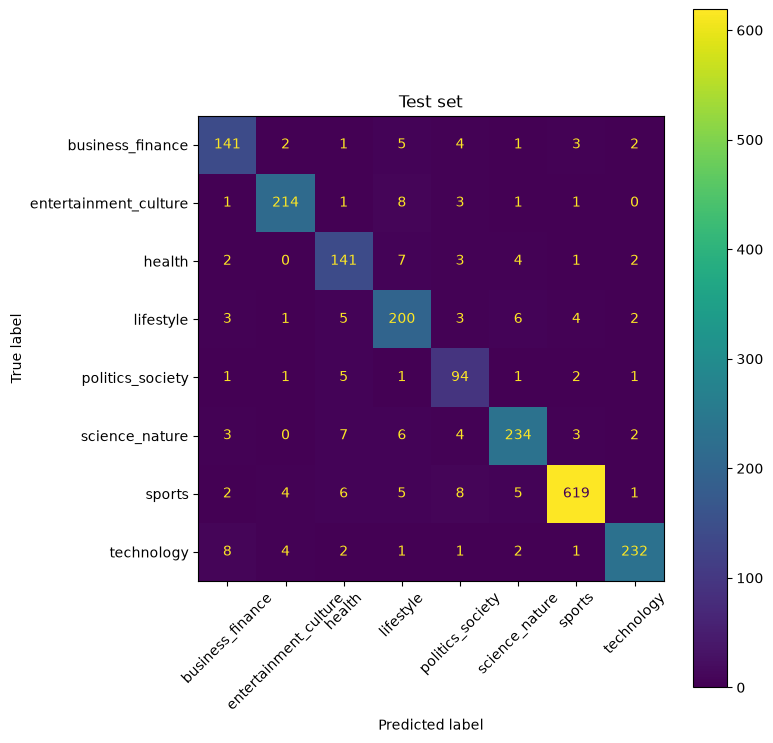

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predicted,
    xticks_rotation=45,
    ax=ax,
)
ax.set_title("Test set")
fig.tight_layout()

## Terms the model relies on

For each class, these are the terms with the largest logistic-regression weights. They are a check that the TF–IDF features line up with the topic, not a full explanation of every prediction.

In [9]:
feature_names = model.named_steps["tfidf"].get_feature_names_out()
coefficients = model.named_steps["clf"].coef_

for class_index, label in enumerate(model.named_steps["clf"].classes_):
    top_indexes = coefficients[class_index].argsort()[-10:][::-1]
    terms = ", ".join(feature_names[index] for index in top_indexes)
    print(f"{label}: {terms}")

business_finance: financial, bitcoin, job, bank, market, employers, crypto, jobs, nike, social security
entertainment_culture: theatre, film, album, artist, cast, music, musical, actor, series, episode
health: health, drug, mental health, mental, gambling, medical, drugs, patients, medicines, treatment
lifestyle: fishing, fashion, beauty, trail, miss, pageant, fish, tesla, vehicles, restaurant
politics_society: students, university, student, education, minister, college, academic, archaeological, universities, learning
science_nature: energy, brain, wildlife, scientists, fossil, animals, quantum, study, earth, researchers
sports: season, team, championship, champion, golf, club, round, race, players, player
technology: robots, pokémon, game, robot, robotics, apple, samsung, games, steam, ai


## A few test mistakes

Five test articles the model labeled incorrectly. The snippet is the start of the body, which is enough to see whether the article really sits on the boundary between two topics.

In [10]:
mistakes = test_df.loc[test_df["label"].to_numpy() != test_predicted].copy()
mistakes["predicted"] = test_predicted[test_df["label"].to_numpy() != test_predicted]
mistakes["snippet"] = mistakes["body"].str.replace(r"\s+", " ", regex=True).str.slice(0, 280)

print(f"Test mistakes: {len(mistakes):,} of {len(test_df):,}")
mistakes[["title", "label", "predicted", "snippet"]].head(5)

Test mistakes: 163 of 2,038


,title,label,predicted,snippet
979,"Adani Enterprises, UAE's IHC to invest ₹1.08 l...",business_finance,science_nature,Adani Enterprises and UAE's International Hold...
3777,70-ton Messi statue sparks debates due to cont...,entertainment_culture,sports,After a 26-m tall statue was built in Argentin...
10803,Mexico fans sent safety warning over World Cup...,science_nature,sports,Mexican President Claudia Sheinbaum has urged ...
2995,Fireworks aren't the only July Fourth danger. ...,science_nature,health,The July Fourth holiday is one of the busiest ...
9872,Tour de France Teams Carry Enough Bikes and Wh...,sports,lifestyle,Teams transport enough tech around the Tour de...
